# Programmation Python  pour les mathématiques

**Julien Guillod**, [Sorbonne Université](http://www.sorbonne-universite.fr/),
Licence <a href="https://creativecommons.org/licenses/by-nc-nd/4.0/">CC BY-NC-ND</a>

L'entier des chapitres est disponible au format
[HTML](https://python.guillod.org//) et [PDF](https://python.guillod.org//python.pdf).
Ce notebook peut également être exécuté sur [GESIS](https://notebooks.gesis.org/binder/v2/gh/guillod/python/master?filepath=chap05.ipynb).

# 5 Intégration

<div id="ch:integration"></div>

Le but est d'obtenir une approximation d'une intégrale définie du type

$$
J = \int_a^b f(x) \mathrm{d} x
$$

pour une certaine fonction $f:[a,b] \to \mathbb{R}$ trop compliquée pour *a priori* déterminer la valeur de $J$ à la main.
Des méthodes d'approximations déterministes et probabilistes seront introduites pour obtenir une approximation de $J$.

**Concepts abordés:**

* méthodes classiques (rectangles, trapèzes et Simpson)

* méthode de Monte-Carlo

* vitesse convergence

* statistiques



# Exercice 5.1: Méthode des rectangles

<div id="exer:integration-rectangles"></div>

La méthode des rectangles est basée sur la définition de l'intégrale au sens de Riemann. La première étape est de découper l'intervalle $[a,b]$ en $N$ intervalles $[x_n,x_{n+1}]$ de même taille $\delta=\frac{b-a}{N}$, *i.e.* $x_n = a+n\delta$ pour $n\in\{0,1,\dots,N-1\}$ La seconde étape consiste à supposer que la fonction $f$ est constante sur chaque intervalle $[x_n,x_{n+1}]$, donc à faire l'approximation

$$
J_n = \int_{x_n}^{x_{n+1}} f(x) \mathrm{d} x \approx \delta f(\tilde{x}_n)
$$

pour $\tilde{x}_n$ une certaine valeur à choisir dans l'intervalle $[x_n,x_{n+1}]$. Le choix de $\tilde{x}_n$ peut par exemple être fait par $\tilde{x}_n = x_n + \alpha\delta$ avec $\alpha\in[0,1]$. Finalement l'approximation de $J$ est donnée par la somme des approximations de $J_n$,

$$
\tilde{J} = \sum_{n=0}^{N-1} \delta f(\tilde{x}_n)\,.
$$

En supposant que $f\in C^1([a,b])$, alors il est possible de montrer que la méthode des rectangles converge et que sa vitesse de convergence est d'ordre un. Une méthode numérique est dite d'ordre $k$ si l'erreur entre l'approximation numérique et le résultat exacte est de l'ordre de $\frac{1}{N^k}$.

**Indication:**
Pour chaque valeur de $n$, et $x\in[x_{n},x_{n+1}]$, par le théorème
des accroissements finis, il existe $c_{n}$ tel que:

$$
f(x)-f(\tilde{x}_{n})=(x-\tilde{x}_{n})f^{\prime}(c_{n})\,.
$$

Comme $f^{\prime}$ est continue sur $[a,b]$, alors

$$
\sup_{x\in[a,b]}|f^{\prime}(x)|\leq M\,,
$$

et donc

$$
|f(x)-f(\tilde{x}_{n})|\leq M|x-\tilde{x}_{n}|\leq M\delta\leq\frac{M(b-a)}{N}\,.
$$

Ainsi

$$
\begin{align*}
E_{N} & = \left|J-\tilde{J}\right| = \left|\sum_{n=0}^{N-1}\left(\int_{x_{n}}^{x_{n+1}}f(x)\,\mathrm{d} x-\delta f(\tilde{x}_{n})\right)\right|\\ 
 & \leq\sum_{n=0}^{N-1}\left|\int_{x_{n}}^{x_{n+1}}\left(f(x)-f(\tilde{x}_{n})\right)\,\mathrm{d} x\right|\leq\sum_{n=0}^{N-1}\int_{x_{n}}^{x_{n+1}}|f(x)-f(\tilde{x}_{n})|\,\mathrm{d} x\\ 
 & \leq\sum_{n=0}^{N-1}\int_{x_{n}}^{x_{n+1}}\frac{M(b-a)}{N}\,\mathrm{d} x\leq\frac{M(b-a)^{2}}{N}\,.
\end{align*}
$$

Par conséquent si $f\in C^1([a,b])$, alors la méthode des rectangles est d'ordre un.

**a)**
Choisir une fonction continue $f:[a,b]\to\mathbb{R}$ et définir la fonction Python `f(x)` correspondante. Pour tester le code, il est judicieux de choisir une fonction $f$ dont l'intégrale peut être facilement calculable à la main.

**Indication:**
La liste des fonctions mathématiques de base disponibles en Python dans le module `math` est disponible dans la documentation [ici](https://docs.python.org/fr/3/library/math.html). Par exemple pour calculer $e^\pi$:

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
def f(x):
    return 3*x**2 + 2*x - 1 + math.sin(2*math.pi*x)
def g(x):
    return 1/(1+x**2)

On choisit la fonction $f(x)=ln(x)$ (livre de Sylvie Guèrre-Delabrière, exercice 6.3, page 140), facilement intégrable par parties, dans l'intervalle $[1,n]$ pour $n\in\mathbb{N}^{*}$

A noter que Numpy définit également des fonctions mathématiques, voir [ici](https://docs.scipy.org/doc/numpy/reference/routines.math.html).




**b)**
Écrire une fonction `rectangles(f,a,b,N)` qui retourne l'approximation de l'intégrale $J$ par la méthode des rectangles par exemple en choisissant $\tilde{x}_n=x_n$, *i.e.* le bord gauche de l'intervalle $[x_n,x_{n+1}]$.

**Indication:**
Il n'est pas nécessaire de stoker toutes les valeurs des approximations de $J_n$, mais il est possible d'incrémenter une variable pour chaque approximation de $J_n$.



In [2]:
def rectangles(f,a,b,N):
    delta = (b-a)/N # taille des intervalles
    x = np.arange(a,b,delta)
    y = f(x)
    area = 0
    for index in range(N - 1):
        area = area + y[index]*(x[index+1]-x[index])
    return area

assert rectangles(f,1,2,40)==0.36058977068664333

TypeError: only size-1 arrays can be converted to Python scalars


**c)**
Modifier la fonction précédente pour que celle-ci prenne un paramètre optionnel `alpha` déterminant le choix du paramètre $\alpha\in[0,1]$.



In [3]:
def rectangles1(f,a,b,N,alpha):
    delta = (b-a)/N # taille des intervalles
    print(delta)
    shift = alpha * delta
    x = np.arange(a,b,delta) + shift
    print(x)
    y = f(x)
    area = 0
    for index in range(N - 1):
        # area = area + y[index]*(x[index+1]-x[index])
        area = area + y[index]*delta
    return area

rectangles1(f,1,2,10,0.5)

0.1
[1.05 1.15 1.25 1.35 1.45 1.55 1.65 1.75 1.85 1.95]


TypeError: only size-1 arrays can be converted to Python scalars



**d)**
Écrire une fonction `plot_rectangles(f,a,b,N,alpha=0.5)` qui représente graphiquement l'approximation par la méthode des rectangles.



[0.02 0.12 0.22 0.32 0.42 0.52 0.62 0.72 0.82 0.92]
integrale = 0.8502000000000003


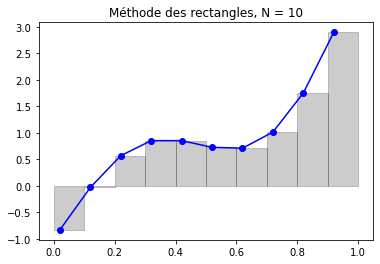

In [20]:
def plot_rectangles(f,a,b,N,alpha=0.2):
    delta = (b-a)/N
    shift = alpha * delta # éventuel choix dans l'intervalle
    x = np.arange(a,b,delta) + shift
    print(x)
    f = np.vectorize(f)
    y = f(x)
    plt.plot(x,y,'bo-')
    area = 0
    bx = np.linspace(a,b,N+1,endpoint=True)
    for index in range(N):
        area = area + y[index]*delta
        x_sommet = [bx[index], bx[index], bx[index+1], bx[index+1], bx[index]]
        y_sommet = [0, y[index], y[index], 0, 0] 
        plt.fill(x_sommet,y_sommet,'k',edgecolor='k',alpha=0.2)
    print("integrale =", area)
    plt.title('Méthode des rectangles, N = {}'.format(N))
    plt.show()

plot_rectangles(f,0,1,10,alpha=0.2)


**e)**
Déterminer empiriquement la vitesse de convergence de la méthode des rectangles en fonction de $N$.



TypeError: only size-1 arrays can be converted to Python scalars

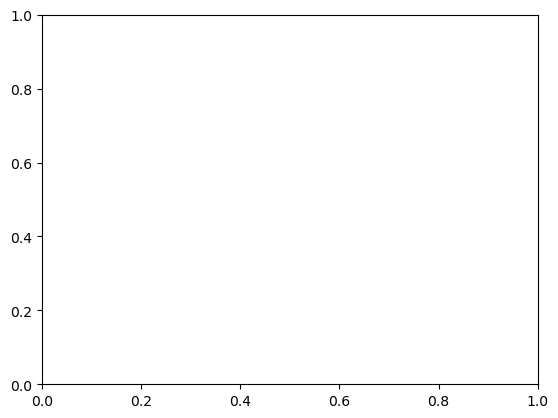

In [4]:
from sympy import *
import pprint
t=Symbol('t',real=True)
fig,ax = plt.subplots()
N = np.arange(1,100,1)
y_obs=list()
y_calc=list()
y_diff=list()
for n in N:
    y_obs.append(rectangles(f,1,2,n))
    y_calc.append(integrate(log(t),(t,1,2)).doit().evalf())
y_diff= [y_calc[i]-y_obs[i] for i in range(0,len(y_obs))]
out=N,y_diff
ax.plot(N,y_diff,'o',label='observé')
ax.plot(N,1/N,label=r'$\frac{1}{n}$')
ax.plot(N,1/N**2,label=r'$\frac{1}{n^2}$')
ax.plot(N,1/N**(0.5),label=r'$\frac{1}{n^{0.5}}$')
plt.xlim(0,100)
plt.ylim(0,0.5)
ax.set_xlabel('N')
ax.set_ylabel('différence')
ax.set_title("Estimation de la vitesse de convergence")
ax.legend(loc='upper right')
plt.show()
# pprint.pprint(out)

Dans la figure on voit que la différence entre la valeur théorique de l'intégrale et la valeur estimée s'ajuste à la courbe pour $\frac{1}{N}$, c'est-à-dire est d'ordre un.

# Exercice 5.2: Méthode des trapèzes

<div id="exer:integration-trapezes"></div>

La méthode des trapèzes est basée sur une approximation linéaire sur chaque intervalle $[x_n,x_{n+1}]$, plus spécifiquement:

$$
J_n = \int_{x_n}^{x_{n+1}} f(x) \mathrm{d} x \approx \delta \frac{f(x_n) + f(x_{n+1})}{2} \,.
$$

**a)**
Écrire une fonction python `trapezes(f,a,b,N)` qui retourne l'approximation de l'intégrale $J$ par la méthode des trapèzes. Tester la fonction `trapezes(f,a,b,N)` pour différentes fonctions $f$.



In [18]:
def trapezes(f,a,b,N):
    delta = (b - a)/N
    x = np.linspace(a,b,N+1)
    print(x)
    f = np.vectorize(f)
    y = f(x)
    print(len(y))
    area = (delta/2) * np.sum(y[1:] + y[:-1])
    return area

def trapezes2(f,a,b,N):
    delta = (b-a)/N
    J = delta*(f(a)+f(b))/2
    for i in range(1,N):
        x = a + delta*i
        J += delta*f(x)
    return J

def trapezes1(f,a,b,N):
    delta = (b - a)/N
    x = np.linspace(a,b,N+1)
    f = np.vectorize(f)
    y = f(x)
    area = (delta/2) * np.sum(y[1:] + y[:-1])
    plt.plot(x,y,label=f'{f}')
    # X=np.linspace(a,b,100)
    # Y=f(X)
    #
    for i in range(N):
        xs = [x[i],x[i],x[i+1],x[i+1]]
        ys = [0,f(x[i]),f(x[i+1]),0]
        plt.fill(xs,ys,color='k',alpha=0.2)
    # plt.title(r'Méthode des trapèzes, area={int:.5f}, N={number:}'.format(int=area,number=N))
    plt.title(f'Méthode des trapèzes, $J^n$:{area}, {N}')
    plt.legend(loc='upper left')
    plt.show()

print(trapezes(f,0,1,20))
print(trapezes2(f,0,1,20))    

[0.   0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65
 0.7  0.75 0.8  0.85 0.9  0.95 1.  ]
21
1.0012500000000002
1.0012500000000002



**b)**
L'implémentation de votre fonction `trapezes(f,a,b,N)` est-elle optimale quant au nombre d'évaluations de $f$ effectuées par rapport au nombre d'évaluations nécessaires ? Une implémentation optimale de la fonction `trapezes(f,a,b,N)` devrait effectuer $N+1$ évaluations de $f$.



En effet, $N+1$ evaluations. Cette évaluation est faite une seule fois ligne 4. L'évaluation de la ligne 7 sert uniquement à dessiner le graphe de la fonction $f$ sur 100 points.


**c)**
Déterminer empiriquement la vitesse de convergence de la méthode des trapèzes en fonction de $N$.



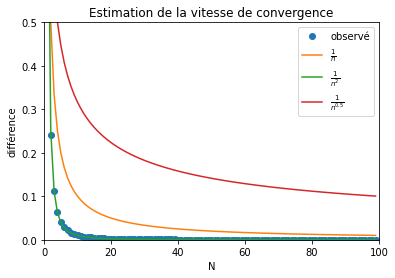

In [51]:
from sympy import *
import pprint
t=Symbol('t',real=True)
fig,ax = plt.subplots()
N = np.arange(1,100,1)
y_obs=list()
y_calc=list()
y_diff=list()
for n in N:
    y_obs.append(trapezes(f,1,5,n))
    y_calc.append(integrate(log(t),(t,1,5)).doit().evalf())
y_diff= [y_calc[i]-y_obs[i] for i in range(0,len(y_obs))]
out=N,y_diff
ax.plot(N,y_diff,'o',label='observé')
ax.plot(N,1/N,label=r'$\frac{1}{n}$')
ax.plot(N,1/N**2,label=r'$\frac{1}{n^2}$')
ax.plot(N,1/N**(0.5),label=r'$\frac{1}{n^{0.5}}$')
plt.xlim(0,100)
plt.ylim(0,0.5)
ax.set_xlabel('N')
ax.set_ylabel('différence')
ax.set_title("Estimation de la vitesse de convergence")
ax.legend(loc='upper right')
plt.show()
# pprint.pprint(out)

D'après le graphe ci-dessus, pour une décomposition de l'intervalle en $1-99$ parties, la différence entre la valeur calculé et la valeur observée est un $O(\frac{1}{N^2})$


**d)**
<span style="color:red">!</span> Déterminer analytiquement la convergence de la méthode des trapèzes. Quelles sont les hypothèses nécessaires sur $f$ ?



D'après la proposition 6.2.2 du livre de Sylvie Guèrre-Délabrière, à savoir: "Soit $f:[a,b]\longrightarrow \mathbb{R}$ deux fois dérivable sur l'intervalle $[a,b]$ et telle que pour tout $t\in[a,b]$, $\alpha\leq f''(t)\leq \beta$, avec $\alpha,\beta \in \mathbb{R}$, alors pourt tout $n\in \mathbb{N^{*}}$, on a:
$$\frac{\alpha(b-a)^3}{12n^2} \leq \mathcal{E_n} \leq \frac{\beta(b-a)^3}{12n^2}$$
ou $\mathcal{E_n}$  est l'erreur commise en approximant l'intégrale.
La fonction dérivée seconde de $f$ doit être donc bornée sur cet intervalle pour pouvoir calculer l'erreur. 
On applique cette proposition pour le calcul approché de l'intégrale: $$\int_{0}^{1}e^{x^{2}}$$

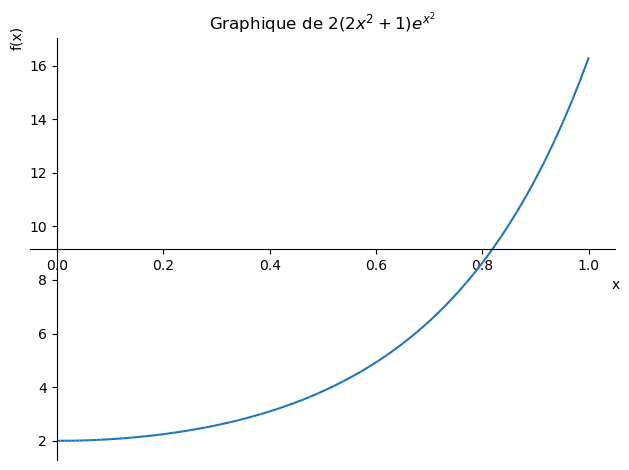

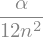

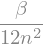

In [5]:
from sympy import *
from IPython.display import display
init_printing(use_unicode=True)
x=Symbol("x",real=True)
n=Symbol("n",real=True)
alpha=Symbol(r"\alpha",real=True)
beta=Symbol(r"\beta",real=True)

#intégrale que l'on veut calculer, entre 0 et 1
expr=(E**x**2)

#les erreurs min et max commises dans cet intervalle pour n=12, sont:
e1=(alpha/(12*n**2))
e2=(beta/(12*n**2))

#dérivée seconde de la fonction 'expr' est continue sur cet intervalle
derivative=diff(expr,x,2)
plot(derivative,(x,0,1), title=f"Graphique de ${latex(derivative)}$")
min=derivative.subs(x,0)
max=derivative.subs(x,1)

#affiche les la précision du calcul: entre 0.001 et 0.009, c'est-à-dire, au centième près
display(e1)
display((e1.subs({n:12,alpha:min})).evalf(1))
display(e2)
display((e2.subs({n:12,beta:max})).evalf(1))

# Exercice 5.3: Méthode de Monte-Carlo

<div id="exer:integration-montecarlo"></div>

La méthode de Monte-Carlo (du nom des casinos, pas d'une personne) est une approche probabiliste permettant d'approximer la valeur d'une intégrale. L'idée de base est que l'intégrale $J$ peut être vue comme l'espérance d'une variable aléatoire uniforme $X$ sur l'intervalle $[a,b]$:

$$
J = \int_a^b f(x) \, \mathrm{d} x = (b-a)\mathbb{E}(f(X)) \,.
$$

Par la loi des grands nombres cette espérance peut être approximée par la moyenne empirique:

$$
\tilde{J} = \frac{b-a}{N}\sum_{i=0}^{N-1} f(x_i) \,,
$$

où les $x_i$ sont tirés aléatoirement dans l'intervalle $[a,b]$ avec une loi de probabilité uniforme.

Il est possible de montrer que $\tilde{J}$ converge vers $J$ comme $N^{-1/2}$ et cela indépendamment de la dimension et de la régularité de $f$.

**Indication:**
Selon le théorème central limite, si $Y_i$ est une suite de variables aléatoires indépendantes d'espérance $\mu$ et de variance $\sigma^2$, alors la variable aléatoire:

$$
S_N = \frac{1}{N}\sum_{i=0}^{N-1} Y_i \,,
$$

a une espérance $\mu$ et une variance:

$$
\mathrm{Var}(S_N) = \frac{\sigma^2}{N} \,.
$$

En prenant $Y_i=f(X_i)$ avec $X_i$ une suite de variables aléatoires indépendantes uniformément distribuées sur $[a,b]$, alors l'espérance de $Y_i$ est la moyenne de $f$ et donc l'espérance de $S_N$ est donnée par:

$$
\mathbb{E}(S_N) = \frac{1}{b-a} \int_a^b f(x) \, \mathrm{d} x \,.
$$

La variance de $Y_i$ est également celle de $f$, $\sigma^2 = \mathrm{Var}(f(X))$ et donc la variance de $S_N$ est:

$$
\mathrm{Var}(S_N) = \frac{\mathrm{Var}(f(X))}{N} \,.
$$

Par conséquent, cela montre que $\tilde{J}$ converge vers $J$ comme $N^{-1/2}$ vu que la variance est proportionnelle à $N^{-1}$.

A remarquer que pour établir ce résultat, aucune condition de régularité sur $f$ n'est nécessaire, de l'intégrabilité suffit.

En pratique la variance de $f$ peut être estimée par la variance empirique.

**a)**
Écrire une fonction `montecarlo(f,a,b,N)` qui détermine une approximation $\tilde{J}$ de $J$ par la méthode de Monte-Carlo.

**Indication:**
Pour générer un vecteur de nombres aléatoires, le sous-module `numpy.random` peut être utile, voir la documentation [ici](https://docs.scipy.org/doc/numpy/reference/random/index.html).



In [60]:
import numpy as np
from sympy import *
import matplotlib.pyplot as plt
def h(x):
    return np.cos(x)

def montecarlo(h,a,b,N):
    x = np.random.uniform(a,b,N)
    # plt.scatter(x,h(x))
    s = sum(h(x))
    A = ((b-a)/N)*s
    return A

display(montecarlo(h,0,1,2000))

# comparaison avec les autres méthodes
display(trapezes(h,0,1,2000))
display(rectangles(h,0,1,2000))
display(integrate(cos(x),(x,0,1)))
integrate(cos(x),(x,0,1)).evalf()


**b)**
Modifier la fonction précédente, pour qu'elle retourne en plus de la moyenne $\tilde{J}$ également la variance empirique

$$
\tilde{V} = \frac{(b-a)^2}{N}\sum_{i=0}^{N-1} \left(f(x_i)-\frac{\tilde{J}}{b-a}\right)^2 \,.
$$


**c)**
Étudier empiriquement la convergence de la méthode de Monte-Carlo en fonction de $N$ en faisant pour chaque valeur de $N$ une statistique sur $k$ exécutions. Plus précisément cela consiste à faire $k$ évaluations de $\tilde{J}$ par la méthode de Monte-Carlo et de calculer la moyenne et la variance des $k$ résultats obtenus.



# Exercice 5.4: <span style="color:red">!</span> Méthode de Simpson

<div id="exer:integration-simpson"></div>

La méthode de Simpson consiste à approximer la fonction $f$ sur chaque intervalle $[x_n,x_{n+1}]$ par un polynôme de degré deux. Le choix le plus naturel est le polynôme $p_n$ de degré deux passant par les points $(x_n,f(x_n))$, $(\frac{x_n+x_{n+1}}{2},f(\frac{x_n+x_{n+1}}{2}))$, et $(x_{n+1},f(x_{n+1}))$.

**a)**
Déterminer la forme explicite du polynôme $p_n$.

**Indication:**
Le polynôme $L(x) = \frac{(x-c)(x-b)}{(a-c)(a-b)}$ prend la valeur un en $x=a$ et la valeur zéro en $x=b$ et $x=c$. Faire une combinaison linéaire de trois polynômes de ce type.




**b)**
Calculer l'approximation donnée par $J_n \approx \int_{x_n}^{x_{n+1}} p_n(x) \mathrm{d} x \,.$

**Indication:**
Il est possible de calculer cette intégrale à la main ou bien de le faire avec le module Sympy, voir la documentation [ici](http://docs.sympy.org/latest/modules/integrals/integrals.html).




**c)**
Simplifier à la main la somme $\tilde{J}$ des approximations de $J_n$.

**Réponse:**
Le résultat est

$$
\tilde{J} = \frac{\delta}{3}\left[\frac{f(b)-f(a)}{2}+\sum_{n=0}^{N-1}\left(f(x_{n})+2f\left(\frac{x_{n}+x_{n+1}}{2}\right)\right)\right] \,.
$$


**d)**
Écrire une fonction `simpson(f,a,b,N)` permettant de calculer une approximation de $J$ avec la méthode de Simpson.




**e)**
Comparer la précision des méthodes des rectangles, des trapèzes et de Simpson en fonction de $N$.



# Exercice 5.5: <span style="color:red">!!</span> Module `scipy.integrate`

Les méthodes d'intégrations précédentes et d'autres sont définies dans le module `scipy.integrate`. Ce module permet en particulier de traiter des cas plus compliqués, par exemple calculer numériquement

$$
E_n(x) = \int_1^\infty \frac{e^{-xt}}{t^n} \mathrm{d} t
$$

à l'aide du code suivant:

In [ ]:
import math, scipy.integrate
def integrand(t, n, x):
    return math.exp(-x*t)/t**n
def E(n, x):
    return scipy.integrate.quad(integrand, 1, math.inf, args=(n, x))[0]
E(4,2)

**a)**
Lire la documentation de ce module disponible [ici](https://docs.scipy.org/doc/scipy/reference/tutorial/integrate.html).

**b)**
A l'aide de ce module, déterminer une approximation de l'intégrale double

$$
I = \int_{0}^{\pi} \left(\int_{0}^{y} x \sin(xy) \,\mathrm{d} x \right) \mathrm{d} y \,.
$$

In [ ]:
scipy.integrate.dblquad(lambda x, y: x*math.sin(x*y), 0, math.pi, 0, lambda x: x)